# Trabajo Práctico Integrador - Introducción al Análisis de Datos

**Caso:** análisis y predicción de cancelaciones en reservas hoteleras.

> Esta plantilla está pensada para construir notebooks independientes y reproducibles. Cada entrega debe poder ejecutarse desde cero, cargando nuevamente el dataset original asignado a la comisión.

## 0.Datos de identificación

- **Apellido y nombre:** Aguillón, Fernando
- **Comisión:** 5
- **Dataset asignado:** E
- **Entrega:** 2
- **Fecha:** 06/09/2026

##1.Importación de librerías

Importar solamente las librerías necesarias para la entrega que se está desarrollando.

In [2]:
# Librerías básicas
install.packages("GGally")
library(ggplot2)
library(GGally)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘patchwork’, ‘ggstats’




##2.Carga del dataset

Cargar el archivo CSV correspondiente a la comisión. El notebook debe funcionar desde el dataset original, no desde objetos creados en otros notebooks.

In [10]:
df_hoteles <- read.csv("/content/hotel booking TPI grupo E.csv")


##3. Limpieza realizada en la entrega 2 con las correcciones correspondientes

In [11]:
df_hoteles <- df_hoteles[, !(names(df_hoteles) %in% c('booking_id', 'meal', 'arrival_date_year', 'arrival_date_month', 'arrival_date_day_of_month', 'arrival_date_week_number' , 'distribution_channel'))]
df_hoteles <- df_hoteles[, !(names(df_hoteles) %in% c('company', 'agent'))]
df_hoteles$country[is.na(df_hoteles$country) | df_hoteles$country == ""] <- "S/C"
df_hoteles$children[is.na(df_hoteles$children)] <- 0
df_hoteles <- df_hoteles[!(df_hoteles$adr < 0 | df_hoteles$adr == 0), ]
df_hoteles <- df_hoteles[!(df_hoteles$adults == 0 & df_hoteles$children == 0 & df_hoteles$babies == 0), ]

##4. Visualizaciones

###4.1 Cancelaciones según tipo de hotel
¿Que reacion hay entre las reservas canceladas y el tipo de hotel elegido?

Se utiliza un grafico de conteo porque permite comparar la cantidad de reservas canceladas y no canceladas segun el tipo de hotel . Es adecuado porque ambas variables son categoricas.

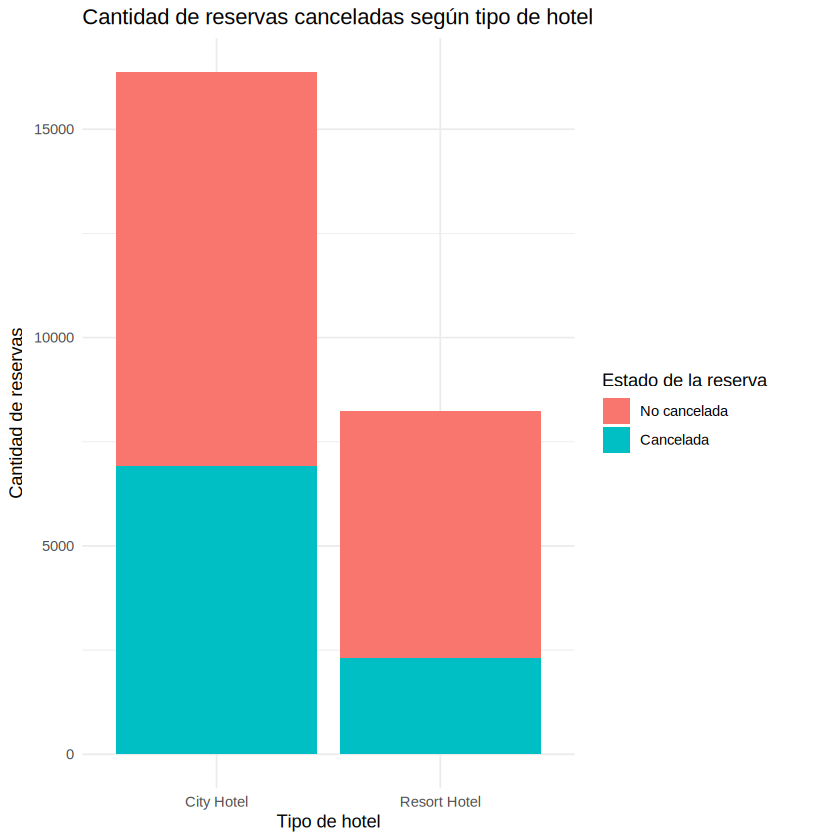

In [22]:
ggplot(df_hoteles, aes(
  x = hotel,
  fill = factor(is_canceled)
)) +
  geom_bar() +
  labs(
    title = "Cantidad de reservas canceladas según tipo de hotel",
    x = "Tipo de hotel",
    y = "Cantidad de reservas",
    fill = "Estado de la reserva"
  ) +
  scale_fill_discrete(
    labels = c(
      "0" = "No cancelada",
      "1" = "Cancelada"
    )
  ) +
  theme_minimal()

Se observa que el `City hotel` concentra una mayor cantidad de reservas, tanto canceladas como no canceladas, pero de manera ligeramente equilibrada. En cambio se ve como `Resort Hotel` tiene un porcentaje menor a un tercio de reservas canceladas. Esto permite comparar el comportamineto de las cancelaciones entre ambos tipos de hotel, dando como resultado que se debe observan el comportamiento en especial de las reservas en `City hotel`.

##4.2 Variable cuantitativa y cancelación
¿Existe una diferencia entre la tarifa promedio por noche entre las reservas canceladas y no canceladas?

Se eligio un diagrama de caja (Box Plot) porque permite comparar la distribucion de uan variable numerica continua, en este caso `adr`, entre dos grupos definidos por una variable categorica, `is_canceled`. Ademas permite observar la mediana, la dispersion y posibles valores atipicos.

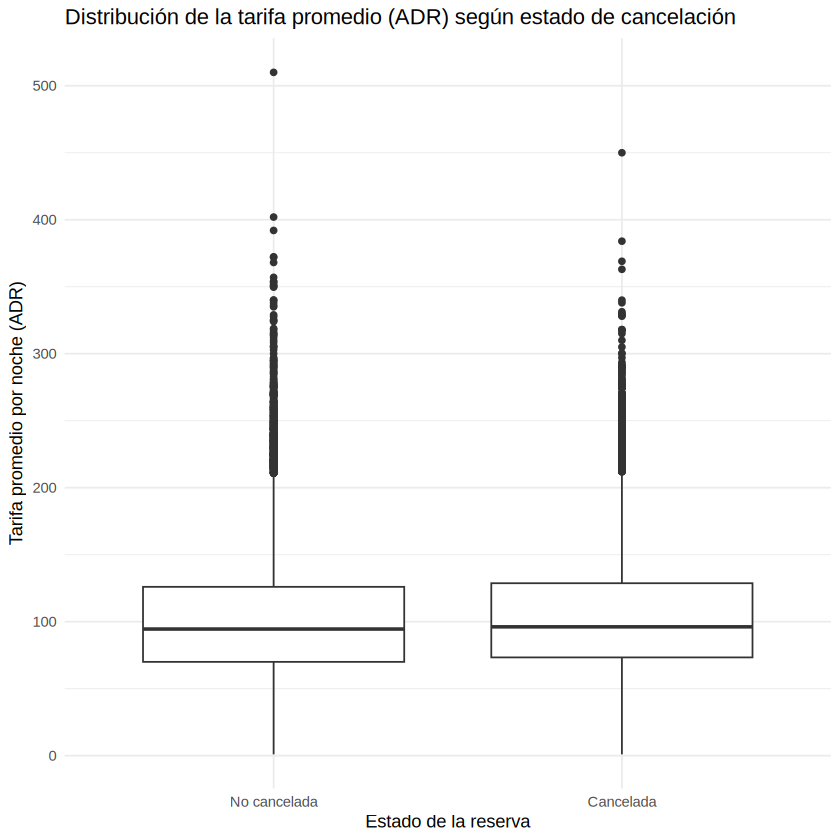

In [16]:

library(ggplot2)

ggplot(df_hoteles, aes(
  x = factor(is_canceled),
  y = adr
)) +
  geom_boxplot() +
  labs(
    title = "Distribución de la tarifa promedio (ADR) según estado de cancelación",
    x = "Estado de la reserva",
    y = "Tarifa promedio por noche (ADR)"
  ) +
  scale_x_discrete(
    labels = c(
      "0" = "No cancelada",
      "1" = "Cancelada"
    )
  ) +
  theme_minimal()



El `adr` presenta una distribucion similar entre reservas canceladas y no canceladdas, pero con una ligera diferencia entre su mediana apensas perceptible. Tambien se ve que ambas opciones presentan valores atipicos similares. En general se puede decir que la tarifa promedio por noche no indica una clara razon de las cancelaciones.

##4.3 Una pregunta propia de análisis
¿Existe una relacion entre la cantidad de dias de anticipacion de una reserva y la probabilidad de ser cancelada?

Se selecciono un diagrama de caja porque permite comparar la distribucion de los dias de anticipacion de las reservas entre aquellas que fueron canceladas y las que no.

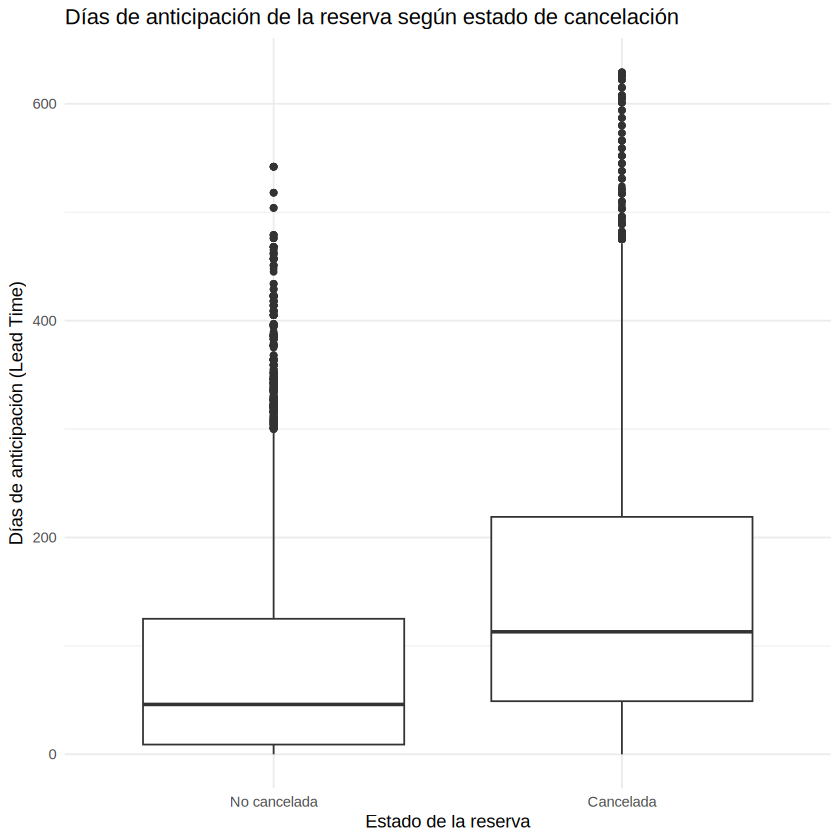

In [20]:
ggplot(df_hoteles, aes(
  x = factor(is_canceled),
  y = lead_time
)) +

  geom_boxplot() +

  labs(
    title = "Días de anticipación de la reserva según estado de cancelación",
    x = "Estado de la reserva",
    y = "Días de anticipación (Lead Time)"
  ) +

  scale_x_discrete(
    labels = c(
      "0" = "No cancelada",
      "1" = "Cancelada"
    )
  ) +

  theme_minimal()

Las reservas canceladas presentan una media notablemente mayor a las no canceladas y una mayor dispersion. Ademas, se observan numerosos valores atipicos, especialmente el las reservas canceladas, con anticipaciones de mas de 600 dias. Esto sugiere una idea al respecto `A mayor anticipacion de la reserva, existe una mayor tendencia a la cancelacion`.